# Imports

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch

In [2]:
import datasets
import numpy as np
import pandas as pd
import sklearn.metrics
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, Qwen2TokenizerFast
import seaborn as sns

c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [3]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [4]:
train_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='train')
test_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='test')

In [5]:
train_df: pd.DataFrame = train_dataset.to_pandas()
test_df: pd.DataFrame = test_dataset.to_pandas()

In [6]:
train_df

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [7]:
test_df

,text,label
0,I love sci-fi and am willing to put up with a ...,0
1,"Worth the entertainment value of a rental, esp...",0
2,its a totally average film with a few semi-alr...,0
3,STAR RATING: ***** Saturday Night **** Friday ...,0
4,"First off let me say, If you haven't enjoyed a...",0
...,...,...
24995,Just got around to seeing Monster Man yesterda...,1
24996,I got this as part of a competition prize. I w...,1
24997,I got Monster Man in a box set of three films ...,1
24998,"Five minutes in, i started to feel how naff th...",1


In [8]:
train_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [9]:
test_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [10]:
train_tokens: list[list[int]] = tokenizer(list(train_dataset["text"]), add_special_tokens=False)["input_ids"]
test_tokens: list[list[int]] = tokenizer(list(test_dataset["text"]), add_special_tokens=False)["input_ids"]

Token indices sequence length is longer than the specified maximum sequence length for this model (718 > 512). Running this sequence through the model will result in indexing errors


In [11]:
train_tokens_len = [len(tokens) for tokens in train_tokens]
test_tokens_len = [len(tokens) for tokens in test_tokens]

<Axes: ylabel='Count'>

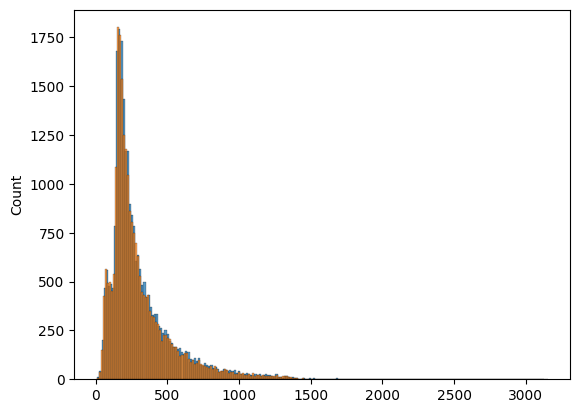

In [12]:
sns.histplot(train_tokens_len)
sns.histplot(test_tokens_len, alpha=0.7)

In [13]:
np.quantile(train_tokens_len, 0.99), np.quantile(test_tokens_len, 0.99)

(np.float64(1204.0), np.float64(1190.0099999999984))

In [14]:
np.quantile(train_tokens_len, 0.95), np.quantile(test_tokens_len, 0.95)

(np.float64(804.0499999999993), np.float64(782.0499999999993))

In [15]:
def truncate_sequence(sequence, max_length):
    if max_length is not None and len(sequence) > max_length:
        return sequence[0 : int(max_length * 0.7)] + sequence[-int(max_length * 0.3) :]
    return sequence

In [16]:
class SequenceDataset(keras.utils.PyDataset):
    def __init__(
        self,
        x,
        y,
        tokenizer,
        max_seq_length: int,
        fixed_seq_length: bool,
        batch_size: int = 128,
        shuffle: bool = True,
        rng: np.random.Generator | None = None,
        **kwargs,
    ):
        super().__init__(**kwargs)
        if rng is None:
            rng = np.random.default_rng()

        self.rng = rng
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.max_seq_length = max_seq_length
        self.fixed_seq_length = fixed_seq_length
        self.tokenizer = tokenizer

        self.raw_text_tokens = [truncate_sequence(seq, self.max_seq_length) for seq in x]
        self.y = np.array(y)

        if fixed_seq_length:
            self.padded_text_tokens = self.pad_sequences(
                self.raw_text_tokens, maxlen=max_seq_length
            )

        self.batch_order: list[np.ndarray] = []
        self.on_epoch_end()

    @classmethod
    def pad_sequences(cls, x, maxlen) -> np.ndarray:
        return keras.utils.pad_sequences(
            x,
            maxlen=maxlen,
            padding="post",
            truncating="post",
            value=tokenizer.pad_token_id,
        )

    def __len__(self):
        return len(self.batch_order)

    def __getitem__(self, idx):
        batch_indices = self.batch_order[idx]

        if not self.fixed_seq_length:
            text_tokens = [self.raw_text_tokens[i] for i in batch_indices]
            max_len = max(len(tokens) for tokens in text_tokens)
            x = self.pad_sequences(text_tokens, maxlen=max_len)
        else:
            x = self.padded_text_tokens[batch_indices]

        return x, self.y[batch_indices]

    def on_epoch_end(self):
        n = len(self.raw_text_tokens)
        if n == 0:
            self.batch_order = []
            return

        boundaries = list(range(0, n, self.batch_size)) + [n]

        if self.fixed_seq_length:
            if self.shuffle:
                indices = self.rng.permutation(n)
            else:
                indices = np.arange(n)
        else:
            lengths = np.array([len(t) for t in self.raw_text_tokens])
            if self.shuffle:
                jitter = self.rng.random(n)
                indices = np.lexsort((jitter, lengths))
            else:
                indices = np.argsort(lengths, kind="stable")

        batches = [
            indices[boundaries[i] : boundaries[i + 1]]
            for i in range(len(boundaries) - 1)
        ]

        if self.shuffle and not self.fixed_seq_length:
            self.rng.shuffle(batches)

        self.batch_order = batches

In [17]:
train_ds = SequenceDataset(
    train_tokens,
    list(train_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
)

In [18]:
test_ds = SequenceDataset(
    test_tokens,
    list(test_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
    shuffle=False
)

In [19]:
batches_positive_counts = [(tokens.shape[-1], sum(labels)) for tokens, labels in train_ds]
x_vals, y_vals = zip(*batches_positive_counts)

<Axes: >

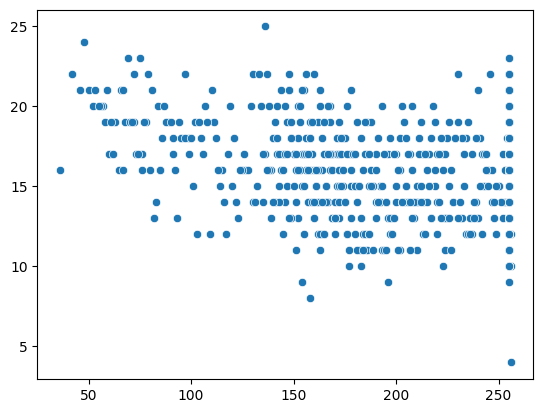

In [20]:
sns.scatterplot(x=x_vals, y=y_vals)

In [21]:
np.corrcoef(x_vals, y_vals)

array([[ 1.        , -0.21510215],
       [-0.21510215,  1.        ]])

# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [22]:
class TokenAndPositionEmbedding(keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.maxlen = maxlen
        self.token_emb = keras.layers.Embedding(
            vocab_size, embed_dim, mask_zero=True
        )
        self.pos_emb = keras.layers.Embedding(maxlen, embed_dim)
        self.cls_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token",
        )

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        positions = keras.ops.arange(seq_len, dtype="int32")
        positions = keras.ops.expand_dims(positions, 0)

        x_emb = self.token_emb(x) + self.pos_emb(positions)

        batch_size = keras.ops.shape(x)[0]
        cls_tokens = keras.ops.broadcast_to(
            self.cls_token, (batch_size, 1, x_emb.shape[-1])
        )
        x_emb = keras.ops.concatenate([cls_tokens, x_emb], axis=1)
        return x_emb

In [23]:
def transformer_block(x, embedding_size, num_heads, block_features, dropout):
    h = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    h = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embedding_size // num_heads,
        dropout=dropout,
    )(h, h)
    h = keras.layers.Dropout(dropout)(h)
    x = keras.layers.Add()([x, h])

    h = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    h = keras.layers.Dense(block_features, activation="gelu")(h)
    h = keras.layers.Dense(embedding_size)(h)
    h = keras.layers.Dropout(dropout)(h)
    x = keras.layers.Add()([x, h])
    return x

In [24]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    name: str | None = None
) -> keras.Model:
    '''Creates a model with Transformer architecture for binary sequence classification.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations 
        max_length: maximal allowed sequence length
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        name: the model name

    Returns:
        The model'''
    tokens = keras.layers.Input(shape=(None,), dtype="int32", name="tokens")

    x = TokenAndPositionEmbedding(max_length, vocab_size, embedding_size)(tokens)
    x = keras.layers.Dropout(0.1)(x)

    for _ in range(num_blocks):
        x = transformer_block(x, embedding_size, num_heads, 256, 0.1)

    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Lambda(lambda t: t[:, 0, :])(x) 
    x = keras.layers.Dense(128, activation="gelu")(x)
    x = keras.layers.Dropout(0.1)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)

    return keras.Model(tokens, out, name=name)

# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [25]:
model = get_model(
    vocab_size=tokenizer.vocab_size,
    embedding_size=256,
    max_length=train_ds.max_seq_length,
    num_blocks=4,
    num_heads=4,
    name="transformer"
)

In [26]:
model.summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tokens (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, None, 256) │  7,879,424 │ tokens[0][0]      │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, None, 256) │          0 │ token_and_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, None, 256) │        512 │ dropout[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, None, 256) │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, None, 256) │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, None, 256) │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, None, 256) │        512 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, None, 256) │     65,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None, 256) │     65,792 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, None, 256) │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, None, 256) │          0 │ add[0][0],        │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, None, 256) │        512 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, None, 256) │    263,168 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, None, 256) │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, None, 256) │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, None, 256) │        512 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, None, 256) │     65,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, None, 256) │     65,792 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, None, 256) │          0 │ dense_3[0][0]   

 Total params: 9,496,065 (36.22 MB)

 Trainable params: 9,496,065 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(
    optimizer=keras.optimizers.AdamW(5e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", "auc"],
)

In [28]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    )
]

In [29]:
model.fit(train_ds, validation_data=test_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 108s 137ms/step - accuracy: 0.7645 - auc: 0.8585 - loss: 0.4631 - val_accuracy: 0.8456 - val_auc: 0.9370 - val_loss: 0.3531
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 106s 136ms/step - accuracy: 0.9007 - auc: 0.9612 - loss: 0.2507 - val_accuracy: 0.8675 - val_auc: 0.9421 - val_loss: 0.3239
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 106s 136ms/step - accuracy: 0.9311 - auc: 0.9776 - loss: 0.1864 - val_accuracy: 0.8546 - val_auc: 0.9395 - val_loss: 0.3700
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 108s 139ms/step - accuracy: 0.9494 - auc: 0.9865 - loss: 0.1397 - val_accuracy: 0.8548 - val_auc: 0.9300 - val_loss: 0.4195
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 107s 137ms/step - accuracy: 0.9619 - auc: 0.9908 - loss: 0.1103 - val_accuracy: 0.8549 - val_auc: 0.9238 - val_loss: 0.4629
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

In [30]:
y_pred = model.predict(test_ds)

782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step


In [31]:
labels = [i for batch in test_ds for i in batch[1]]

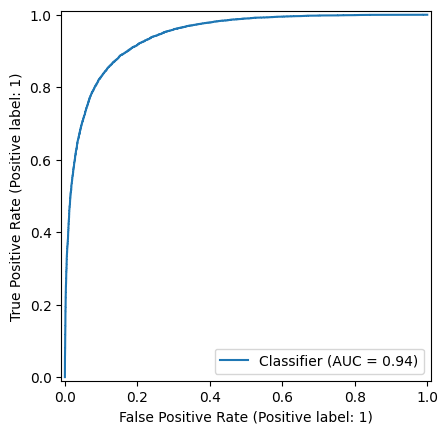

In [32]:
sklearn.metrics.RocCurveDisplay.from_predictions(labels, y_pred)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [44]:
def label_text(
    text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None
) -> int:
    """Computes the model output for `text` and outputs the predicted label

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization

    Return:
        Predicted label"""
    raw_tokens = tokenizer.encode(text, add_special_tokens=False)
    tokens = truncate_sequence(raw_tokens, max_length)

    prediction = model.predict(np.array([tokens]), verbose=False)
    label = int(prediction[0][0] > threshold)
    print("Probability:", prediction[0][0])
    print("Label      :", ["negative", "positive"][label])

    return label

In [45]:
reviews = {
    0: [
        "A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it.",
        "Two hours of my life wasted. The plot makes no sense, the jokes fall flat, and the villain is a cardboard cutout.",
        "Terrible pacing, awful dialogue, and a soundtrack that never shuts up. Even the explosions are boring.",
    ],
    1: [
        "A gripping thriller. Sharp writing, intense performances, and a finale that left me breathless. Highly recommend.",
        "Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch.",
        "Visually stunning and deeply moving. The director crafts a rich world, and the lead performance is Oscar-worthy. Don't miss it.",
    ],
}


In [46]:
for key, texts in reviews.items():
    for text in texts:
        print(text)
        pred = label_text(text, model)
        if pred == key:
            print("✅Correct")
        else:
            print("❌Wrong")
        print()

A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it.
Probability: 0.0034465918
Label      : negative
✅Correct

Two hours of my life wasted. The plot makes no sense, the jokes fall flat, and the villain is a cardboard cutout.
Probability: 0.0030702413
Label      : negative
✅Correct

Terrible pacing, awful dialogue, and a soundtrack that never shuts up. Even the explosions are boring.
Probability: 0.0036089353
Label      : negative
✅Correct

A gripping thriller. Sharp writing, intense performances, and a finale that left me breathless. Highly recommend.
Probability: 0.99671966
Label      : positive
✅Correct

Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch.
Probability: 0.9973878
Label      : positive
✅Correct

Visually stunning and deeply moving. The director crafts a rich world, and the lead performance is Oscar-worthy. Don't miss it.
Probability: 0.9968765
Label     

In [47]:
reviews_ru = {
    0: [
        "Унылый бардак. Деревянная игра актёров, предсказуемый поворот и CGI, будто из видеоигры 2005 года. Пропускайте",
        "Два часа жизни зря. Сюжет не имеет смысла, шутки не срабатывают, а злодей — картонный",
        "Ужасный темп, отвратительные диалоги и саундтрек, который не замолкает. Даже взрывы скучные",
    ],
    1: [
        "Захватывающий триллер. Острая сценарная работа, мощная игра актёров и финал, от которого захватывает дух. Очень рекомендую",
        "Очаровательно и душевно. У актёров отличная химия, юмор попадает в цель, а эмоциональные моменты искренни. Смотреть — одно удовольствие",
        "Визуально потрясающе и глубоко трогательно. Режиссёр создаёт богатый мир, а главная роль достойна „Оскара“. Не пропустите",
    ],
}


In [48]:
for key, texts in reviews_ru.items():
    for text in texts:
        print(text)
        pred = label_text(text, model)
        print()

Унылый бардак. Деревянная игра актёров, предсказуемый поворот и CGI, будто из видеоигры 2005 года. Пропускайте
Probability: 0.263857
Label      : negative

Два часа жизни зря. Сюжет не имеет смысла, шутки не срабатывают, а злодей — картонный
Probability: 0.056871932
Label      : negative

Ужасный темп, отвратительные диалоги и саундтрек, который не замолкает. Даже взрывы скучные
Probability: 0.13695832
Label      : negative

Захватывающий триллер. Острая сценарная работа, мощная игра актёров и финал, от которого захватывает дух. Очень рекомендую
Probability: 0.01278725
Label      : negative

Очаровательно и душевно. У актёров отличная химия, юмор попадает в цель, а эмоциональные моменты искренни. Смотреть — одно удовольствие
Probability: 0.012121528
Label      : negative

Визуально потрясающе и глубоко трогательно. Режиссёр создаёт богатый мир, а главная роль достойна „Оскара“. Не пропустите
Probability: 0.09437377
Label      : negative



# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.

In [ ]:
def attention_heatmap(text: str, model: keras.models.Model):
    sample = tokenizer.encode(text, add_special_tokens=False)
    tokens = ["CLS"] + tokenizer.convert_ids_to_tokens(sample)

    attention = model.get_layer("multi_head_attention")
    embedding = model.get_layer("token_and_position_embedding")

    sample_embed = embedding(np.array([sample]))
    _, attention_scores = attention(
        sample_embed, sample_embed, return_attention_scores=True
    )

    scores = attention_scores[0].cpu().detach().numpy()
    avg_scores = np.mean(scores, axis=0)

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(avg_scores, cmap="viridis", xticklabels=tokens, yticklabels=tokens)
    ax.tick_params(axis="x", rotation=70)
    plt.title("Average Attention Scores (All Heads)")
    plt.xlabel("Source Sequence Position")
    plt.ylabel("Target Sequence Position")
    plt.show()

    cls_attention = scores[:, 0, :]
    num_heads = cls_attention.shape[0]
    _, axes = plt.subplots(num_heads, 1, figsize=(12, num_heads), sharex=True)

    for i in range(num_heads):
        x_labels = tokens if i == num_heads - 1 else False

        sns.heatmap(
            cls_attention[i : i + 1, :],
            ax=axes[i],
            cmap="viridis",
            cbar=False,
            xticklabels=x_labels,
            yticklabels=False,
        )

        axes[i].set_ylabel(f"Head {i}")
        axes[i].tick_params(axis="x", rotation=45)

    plt.suptitle("CLS Token Attention per Head")
    plt.tight_layout()
    plt.show()

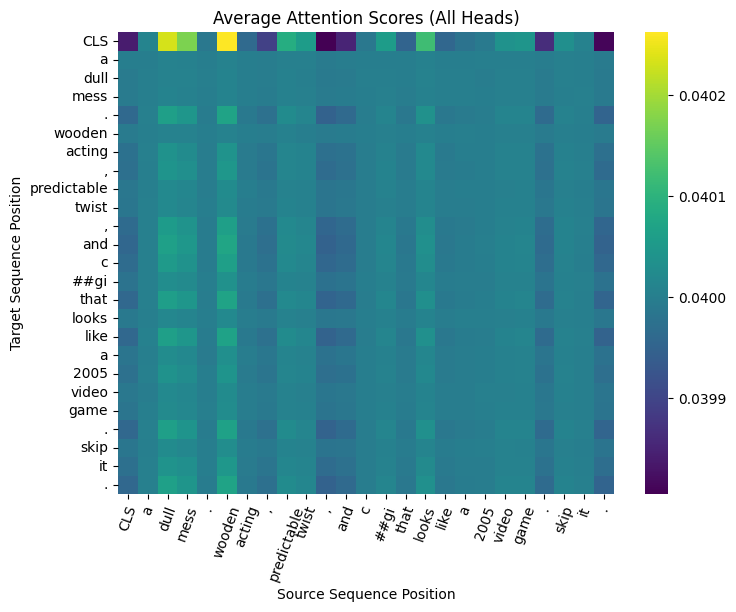

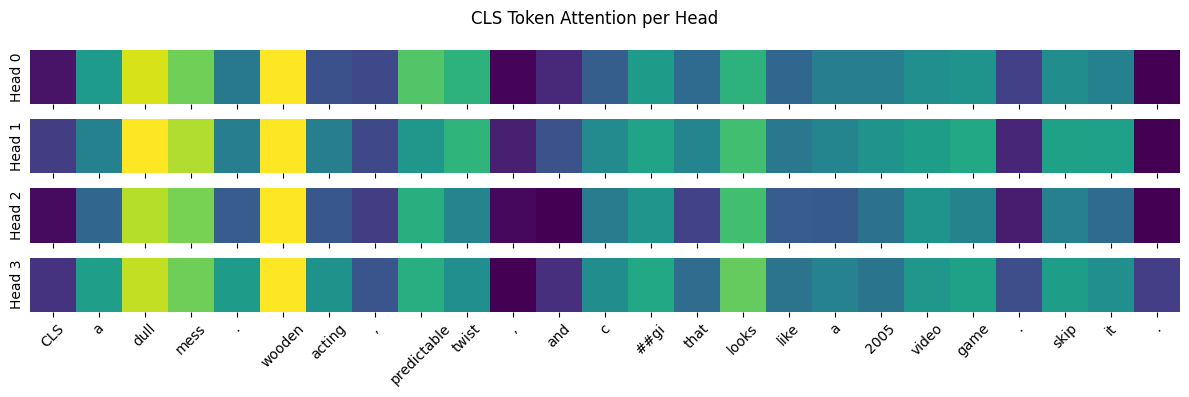

In [111]:
attention_heatmap("A dull mess. Wooden acting, predictable twist, and CGI that looks like a 2005 video game. Skip it.", model)

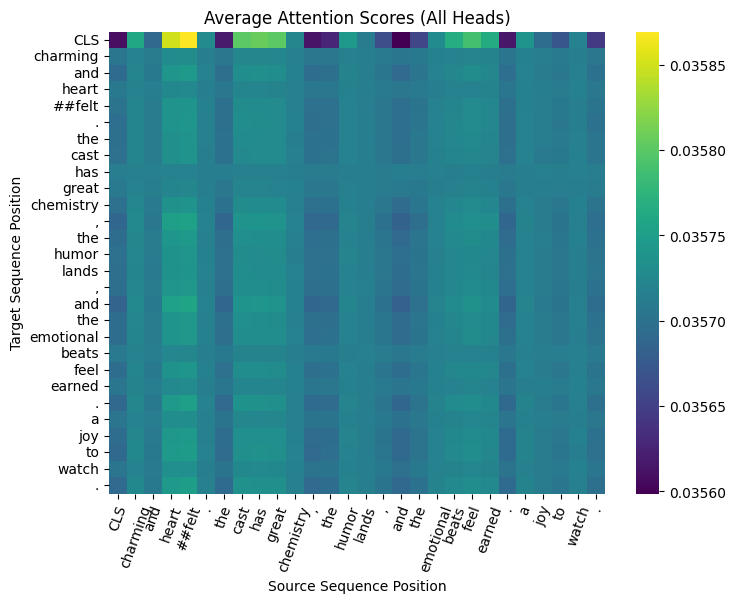

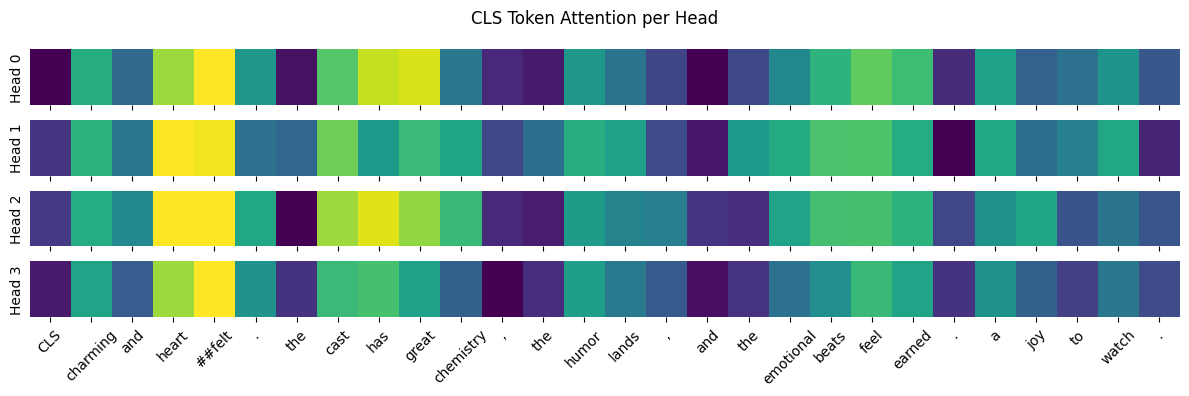

In [112]:
attention_heatmap("Charming and heartfelt. The cast has great chemistry, the humor lands, and the emotional beats feel earned. A joy to watch.", model)